<a href="https://colab.research.google.com/github/Farouk41/Wine_Classification_Project/blob/main/Wine_Classification_Encoder_Decoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Deep Learning Project: Wine Classification Using Encoder–Decoder

### Dataset

* **Dataset:** Wine Dataset from Scikit-learn
* **Number of samples:** 178
* **Number of features:** 13
* **Number of classes:** 3
* **Task:** Multiclass Classification

### Project Tasks

1. **Load Dataset**

   * Load the Wine dataset.
   * Convert it into a DataFrame.
   * Display the features, target, and class distribution.

2. **EDA**

   * Statistical analysis.
   * Distribution plots.
   * Box plots.
   * Correlation heatmap.
   * Class distribution visualization.

3. **Preprocessing**

   * Split features and target.
   * Train-test split (80/20).
   * Apply StandardScaler.

4. **Implement Encoder**

   * Input: 13 features.
   * Dense layers: 64 → 32.
   * Latent representation: 5 features.
   * Activation: ReLU.

5. **Implement Decoder**

   * Input: 5 encoded features.
   * Dense layers: 32 → 64.
   * Output: 13 reconstructed features.

6. **Train Encoder–Decoder**

   * Optimizer: Adam.
   * Loss: MSE.
   * Epochs: 100.
   * Plot training and validation loss.

7. **Extract Encoded Features**

   * Transform original 13 features into 5 encoded features.

8. **Deep Learning Classification**

   * Input: 5 encoded features.
   * Dense layers: 32 → 16.
   * Output layer: 3 neurons.
   * Activation: Softmax.
   * Loss: Sparse Categorical Crossentropy.

9. **Classification Using Original Features**

   * Implement another Deep Learning classification model.
   * Input: 13 features.
   * Dense layers: 64 → 32 → 16.
   * Output: 3 neurons with Softmax.

10. **Evaluate and Compare**

    * Accuracy.
    * Precision.
    * Recall.
    * F1-score.
    * Confusion matrix.

11. **Visualization**
    * Classification loss.
    * PCA visualization of encoded features.

### Final Objective

Compare two Deep Learning classification models:

| Model                                 | Input Features | Output Classes |
| ------------------------------------- | -------------: | -------------: |
| Deep Learning using Original Features |             13 |              3 |
| Deep Learning using Encoder Features  |              5 |              3 |

**No traditional Machine Learning models are required.**


## 1. Load Dataset

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

sns.set_style("whitegrid")

In [ ]:
# Load Wine dataset
wine = load_wine()

# Convert to DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target

print("Shape:", df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
# Features, target and class names
print("Features (13):")
for i, f in enumerate(wine.feature_names, 1):
    print(f"  {i:2d}. {f}")

print("\nTarget classes:", list(wine.target_names))

# Class distribution
class_counts = df["target"].value_counts().sort_index()
class_dist = pd.DataFrame({
    "class": [wine.target_names[i] for i in class_counts.index],
    "count": class_counts.values,
    "percentage %": (class_counts.values / len(df) * 100).round(2)
})
class_dist

Features (13):
   1. alcohol
   2. malic_acid
   3. ash
   4. alcalinity_of_ash
   5. magnesium
   6. total_phenols
   7. flavanoids
   8. nonflavanoid_phenols
   9. proanthocyanins
  10. color_intensity
  11. hue
  12. od280/od315_of_diluted_wines
  13. proline

Target classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,class,count,percentage %
0,class_0,59,33.15
1,class_1,71,39.89
2,class_2,48,26.97


## 2. Exploratory Data Analysis (EDA)

### 2.1 Statistical analysis

In [ ]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### 2.2 Distribution plots

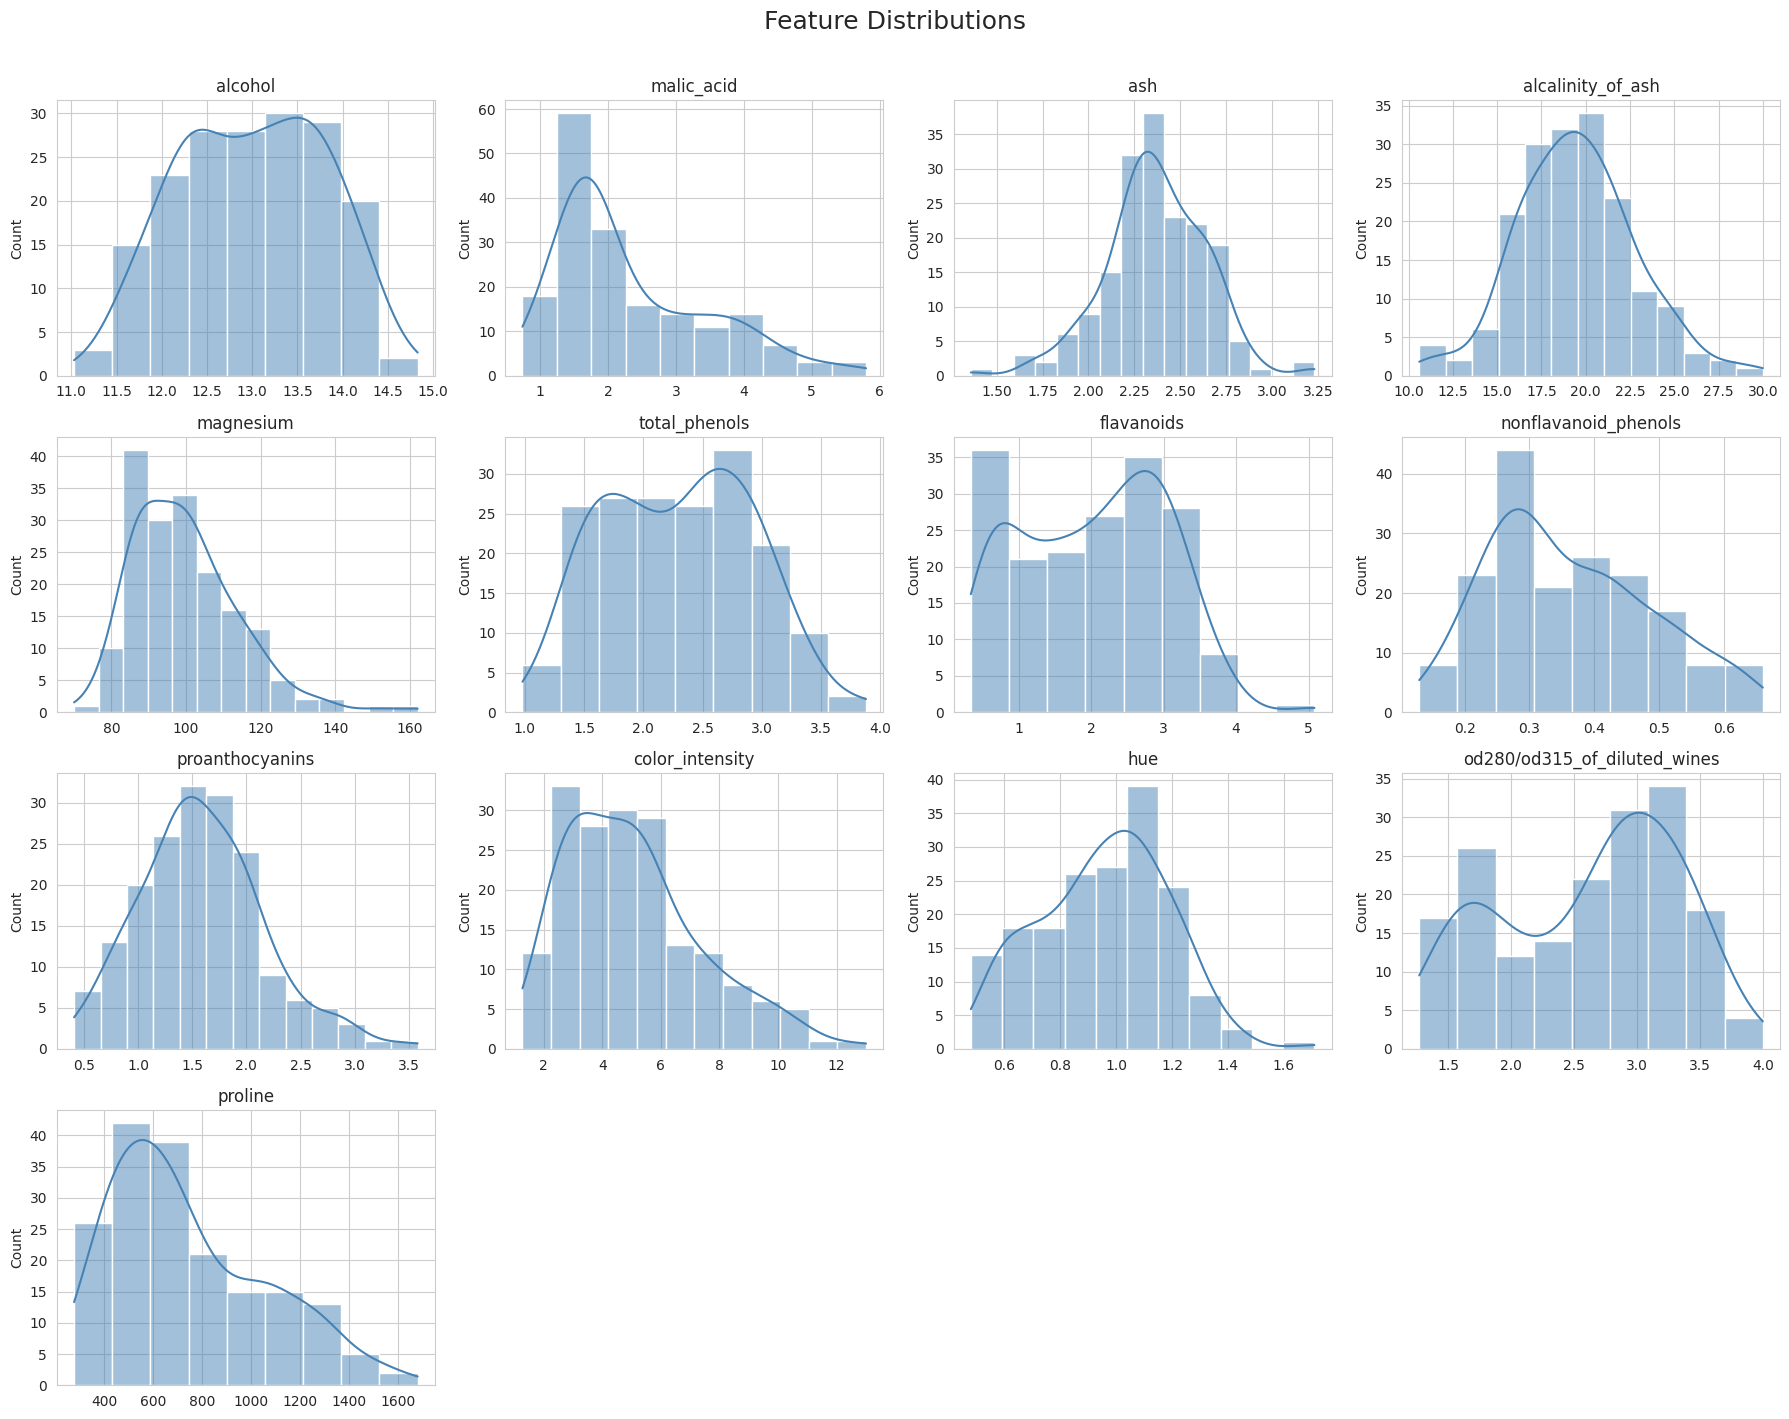

In [ ]:
features = wine.feature_names
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.ravel()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)
    axes[i].set_xlabel("")
for j in range(len(features), len(axes)):
    axes[j].axis("off")
plt.suptitle("Feature Distributions", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

### 2.3 Box plots

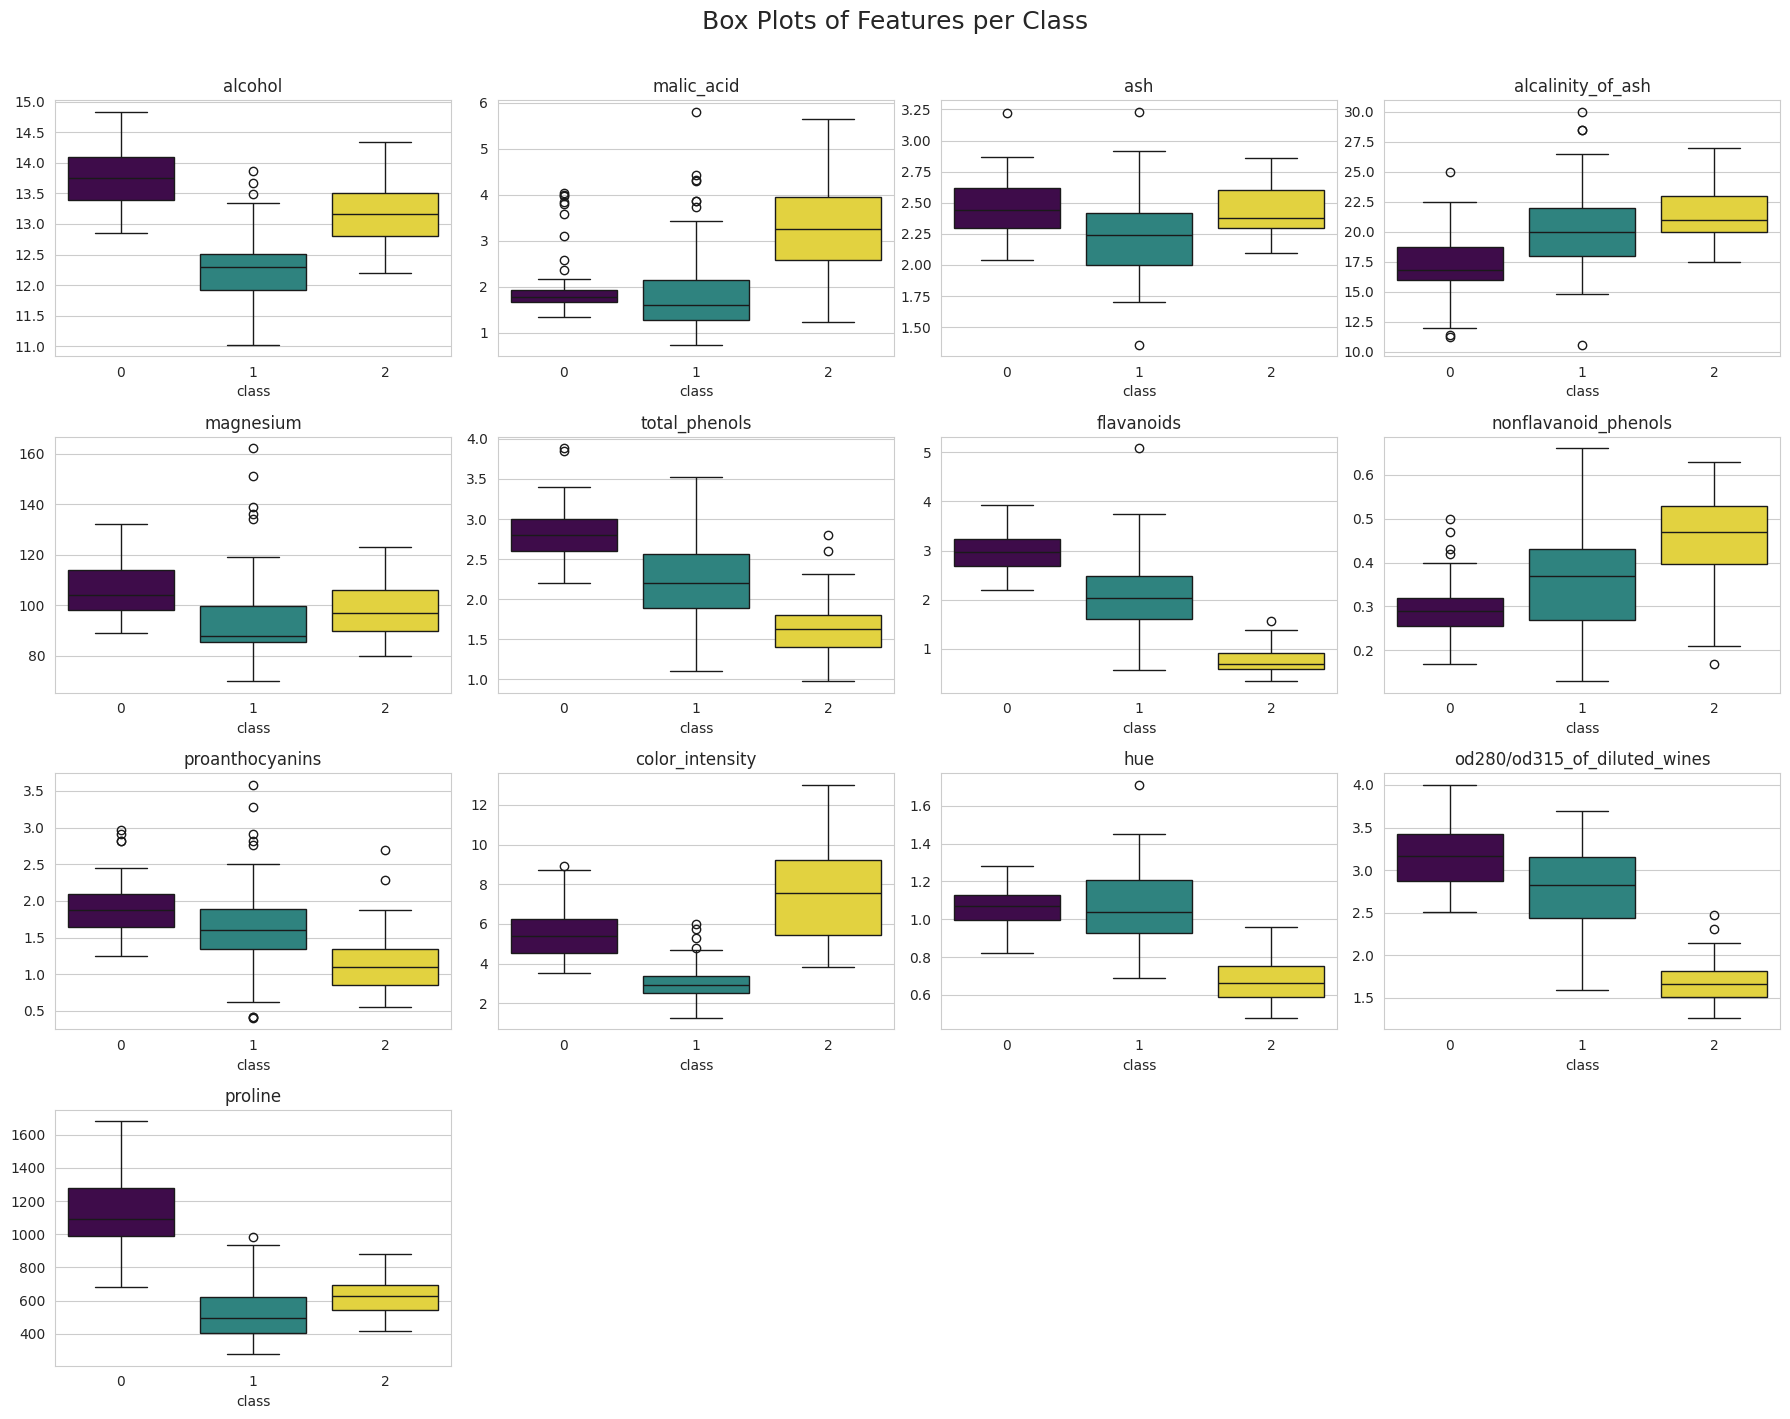

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.ravel()
for i, col in enumerate(features):
    sns.boxplot(data=df, x="target", y=col, hue="target", palette="viridis",
                legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("class")
    axes[i].set_ylabel("")
for j in range(len(features), len(axes)):
    axes[j].axis("off")
plt.suptitle("Box Plots of Features per Class", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

### 2.4 Correlation heatmap

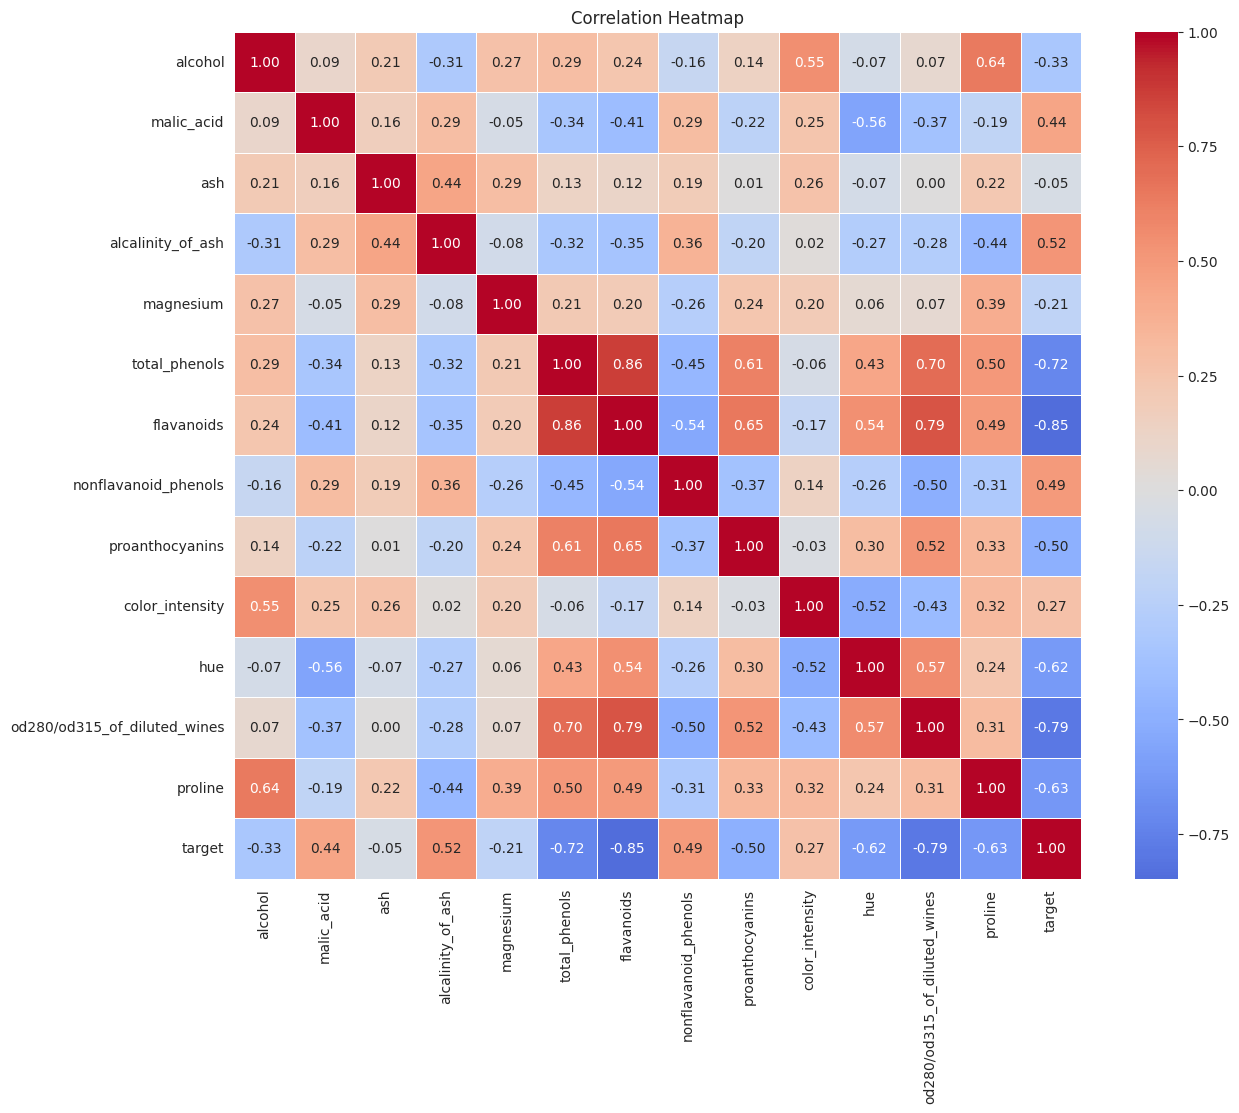

In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True)
plt.title("Correlation Heatmap")
plt.show()

### 2.5 Class distribution visualization

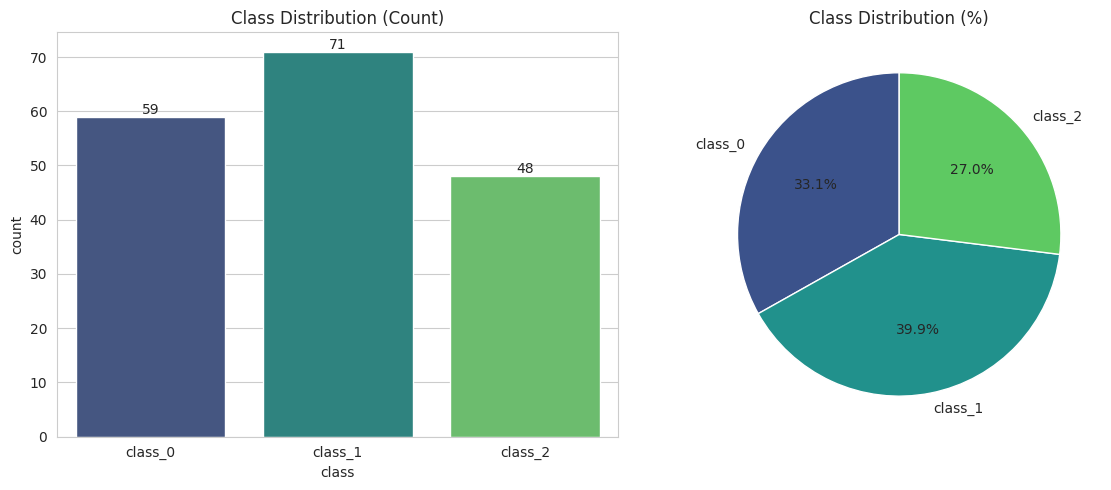

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = [wine.target_names[i] for i in class_counts.index]

sns.countplot(x=df["target"].map(lambda i: wine.target_names[i]),
              hue=df["target"].map(lambda i: wine.target_names[i]),
              order=labels, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Class Distribution (Count)")
axes[0].set_xlabel("class")
for c in axes[0].containers:
    axes[0].bar_label(c)

axes[1].pie(class_counts.values, labels=labels, autopct="%1.1f%%",
            colors=sns.color_palette("viridis", 3), startangle=90)
axes[1].set_title("Class Distribution (%)")
plt.tight_layout()
plt.show()

## 3. Preprocessing

In [ ]:
# Split features and target
X = df.drop("target", axis=1).values
y = df["target"].values

# Train-test split (80/20) - stratified to keep the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# StandardScaler: fit on TRAIN only, then transform both (avoids data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train distribution:", np.bincount(y_train))
print("y_test  distribution:", np.bincount(y_test))

X_train: (142, 13) | X_test: (36, 13)
y_train distribution: [47 57 38]
y_test  distribution: [12 14 10]


## 4. Implement Encoder

`13 → 64 → 32 → 5` (ReLU).  
The latent layer uses ReLU as required by the project description.

In [ ]:
INPUT_DIM = 13
LATENT_DIM = 5

encoder_input = keras.Input(shape=(INPUT_DIM,), name="encoder_input")
x = layers.Dense(64, activation="relu", name="enc_dense_64")(encoder_input)
x = layers.Dense(32, activation="relu", name="enc_dense_32")(x)
latent = layers.Dense(LATENT_DIM, activation="relu", name="latent_5")(x)

encoder = keras.Model(encoder_input, latent, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_64 (Dense)            │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_32 (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_5 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,141 (12.27 KB)

 Trainable params: 3,141 (12.27 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Implement Decoder

`5 → 32 → 64 → 13`. The output layer is linear because the data is standardized (it contains negative values).

In [ ]:
decoder_input = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(32, activation="relu", name="dec_dense_32")(decoder_input)
x = layers.Dense(64, activation="relu", name="dec_dense_64")(x)
decoder_output = layers.Dense(INPUT_DIM, activation="linear", name="reconstruction_13")(x)

decoder = keras.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_32 (Dense)            │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_64 (Dense)            │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction_13 (Dense)       │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,149 (12.30 KB)

 Trainable params: 3,149 (12.30 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train Encoder–Decoder (Autoencoder)

In [ ]:
# Combine encoder + decoder
ae_input = keras.Input(shape=(INPUT_DIM,))
autoencoder = keras.Model(ae_input, decoder(encoder(ae_input)), name="autoencoder")
autoencoder.summary()

autoencoder.compile(optimizer="adam", loss="mse")

# The input is also the target (reconstruction)
ae_history = autoencoder.fit(
    X_train, X_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    shuffle=True,
    verbose=0
)

print(f"Final train loss: {ae_history.history['loss'][-1]:.4f}")
print(f"Final val   loss: {ae_history.history['val_loss'][-1]:.4f}")
print(f"Test reconstruction MSE: {autoencoder.evaluate(X_test, X_test, verbose=0):.4f}")

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 5)              │         3,141 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 13)             │         3,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,290 (24.57 KB)

 Trainable params: 6,290 (24.57 KB)

 Non-trainable params: 0 (0.00 B)

Final train loss: 0.1451
Final val   loss: 0.3164
Test reconstruction MSE: 0.2492


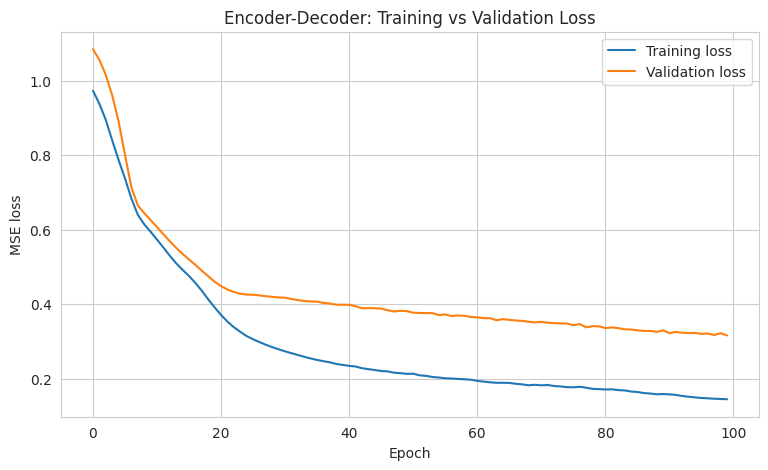

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(ae_history.history["loss"], label="Training loss")
plt.plot(ae_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("Encoder-Decoder: Training vs Validation Loss")
plt.legend(); plt.show()

## 7. Extract Encoded Features

Transform the original 13 features into 5 encoded features using the trained encoder.

In [ ]:
X_train_enc = encoder.predict(X_train, verbose=0)
X_test_enc = encoder.predict(X_test, verbose=0)

print("Original  :", X_train.shape, "->", "Encoded:", X_train_enc.shape)
print("Original  :", X_test.shape,  "->", "Encoded:", X_test_enc.shape)
pd.DataFrame(X_train_enc, columns=[f"latent_{i+1}" for i in range(LATENT_DIM)]).head()

Original  : (142, 13) -> Encoded: (142, 5)
Original  : (36, 13) -> Encoded: (36, 5)


,latent_1,latent_2,latent_3,latent_4,latent_5
0,0.201049,4.392187,0.725430,0.0,1.358906
1,1.306619,8.053048,1.530170,0.0,2.350028
2,0.000000,5.304965,1.367242,0.0,1.592243
3,0.000000,6.624381,1.929607,0.0,2.414800
4,6.070014,0.983732,2.777876,0.0,0.689769


## 8. Deep Learning Classification using Encoded Features (5 → 32 → 16 → 3)

In [ ]:
def build_encoded_classifier():
    model = keras.Sequential([
        keras.Input(shape=(LATENT_DIM,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(3, activation="softmax"),
    ], name="classifier_encoded_features")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

clf_enc = build_encoded_classifier()
clf_enc.summary()

hist_enc = clf_enc.fit(
    X_train_enc, y_train,
    epochs=100, batch_size=16,
    validation_split=0.2, verbose=0
)
print(f"Final train acc: {hist_enc.history['accuracy'][-1]:.4f} | val acc: {hist_enc.history['val_accuracy'][-1]:.4f}")

Model: "classifier_encoded_features"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

Final train acc: 0.9912 | val acc: 1.0000


## 9. Classification using Original Features (13 → 64 → 32 → 16 → 3)

In [ ]:
def build_original_classifier():
    model = keras.Sequential([
        keras.Input(shape=(INPUT_DIM,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(3, activation="softmax"),
    ], name="classifier_original_features")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

clf_orig = build_original_classifier()
clf_orig.summary()

hist_orig = clf_orig.fit(
    X_train, y_train,
    epochs=100, batch_size=16,
    validation_split=0.2, verbose=0
)
print(f"Final train acc: {hist_orig.history['accuracy'][-1]:.4f} | val acc: {hist_orig.history['val_accuracy'][-1]:.4f}")

Model: "classifier_original_features"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,555 (13.89 KB)

 Trainable params: 3,555 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

Final train acc: 1.0000 | val acc: 1.0000


## 10. Evaluate and Compare

In [ ]:
class_names = list(wine.target_names)

y_pred_enc = np.argmax(clf_enc.predict(X_test_enc, verbose=0), axis=1)
y_pred_orig = np.argmax(clf_orig.predict(X_test, verbose=0), axis=1)

def get_metrics(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

results = pd.DataFrame({
    "Original Features (13)": get_metrics(y_test, y_pred_orig),
    "Encoder Features (5)":   get_metrics(y_test, y_pred_enc),
}).T.round(4)
results

,Accuracy,Precision,Recall,F1-score
Original Features (13),0.9444,0.9514,0.9444,0.9432
Encoder Features (5),0.9444,0.9466,0.9444,0.9443


In [ ]:
for name, pred in [("Original Features (13)", y_pred_orig), ("Encoder Features (5)", y_pred_enc)]:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))

Original Features (13)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.80      0.89        10

    accuracy                           0.94        36
   macro avg       0.96      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36

Encoder Features (5)
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



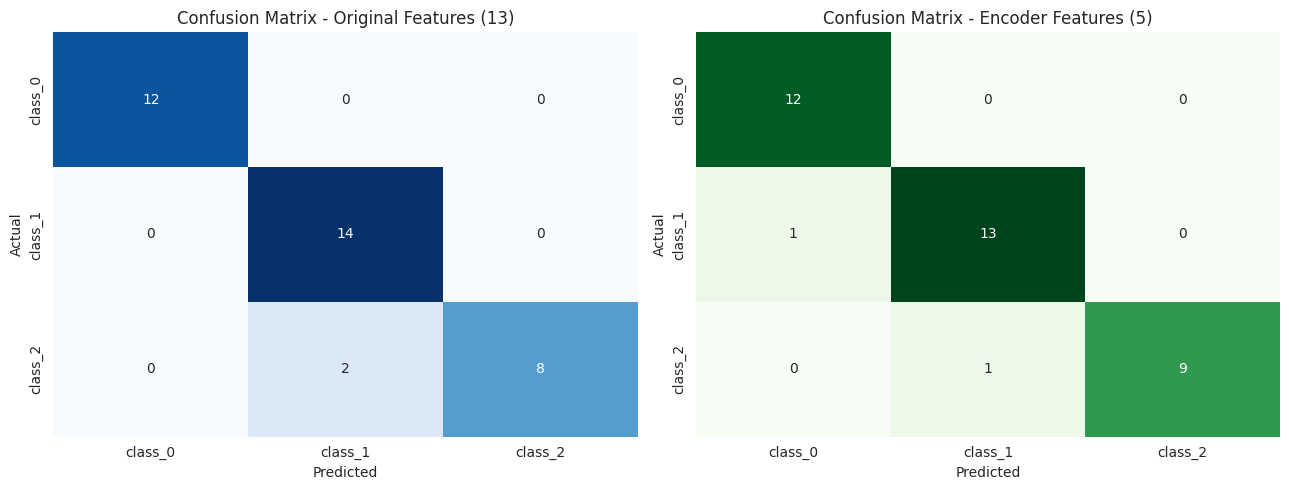

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred, cmap) in zip(axes, [
        ("Original Features (13)", y_pred_orig, "Blues"),
        ("Encoder Features (5)",   y_pred_enc,  "Greens")]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

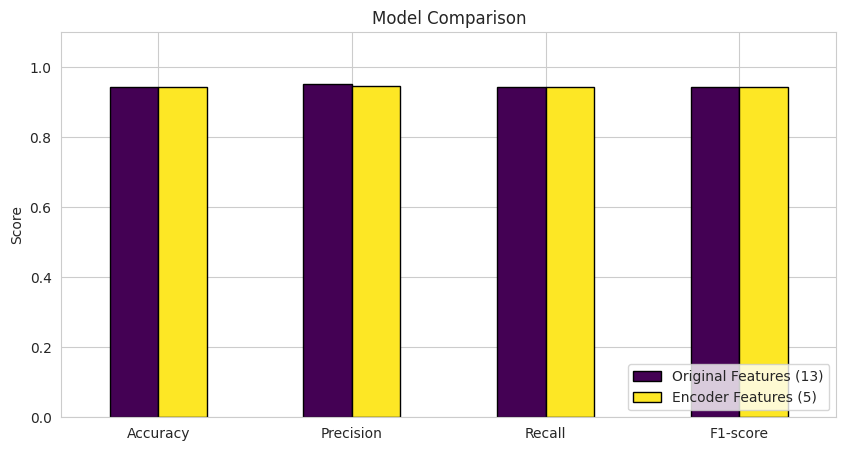

In [ ]:
# Metrics comparison bar chart
results.T.plot(kind="bar", figsize=(10, 5), colormap="viridis", edgecolor="black")
plt.title("Model Comparison")
plt.ylabel("Score"); plt.ylim(0, 1.1); plt.xticks(rotation=0)
plt.legend(loc="lower right"); plt.show()

## 11. Visualization

### 11.1 Classification loss

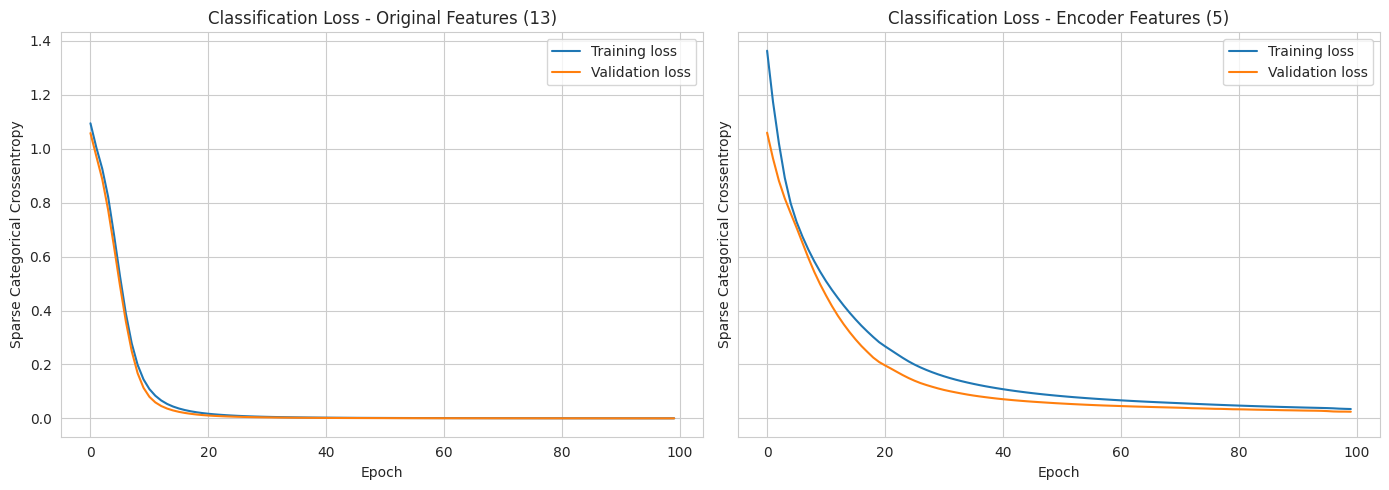

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, h) in zip(axes, [("Original Features (13)", hist_orig),
                                ("Encoder Features (5)", hist_enc)]):
    ax.plot(h.history["loss"], label="Training loss")
    ax.plot(h.history["val_loss"], label="Validation loss")
    ax.set_title(f"Classification Loss - {name}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Sparse Categorical Crossentropy")
    ax.legend()
plt.tight_layout(); plt.show()

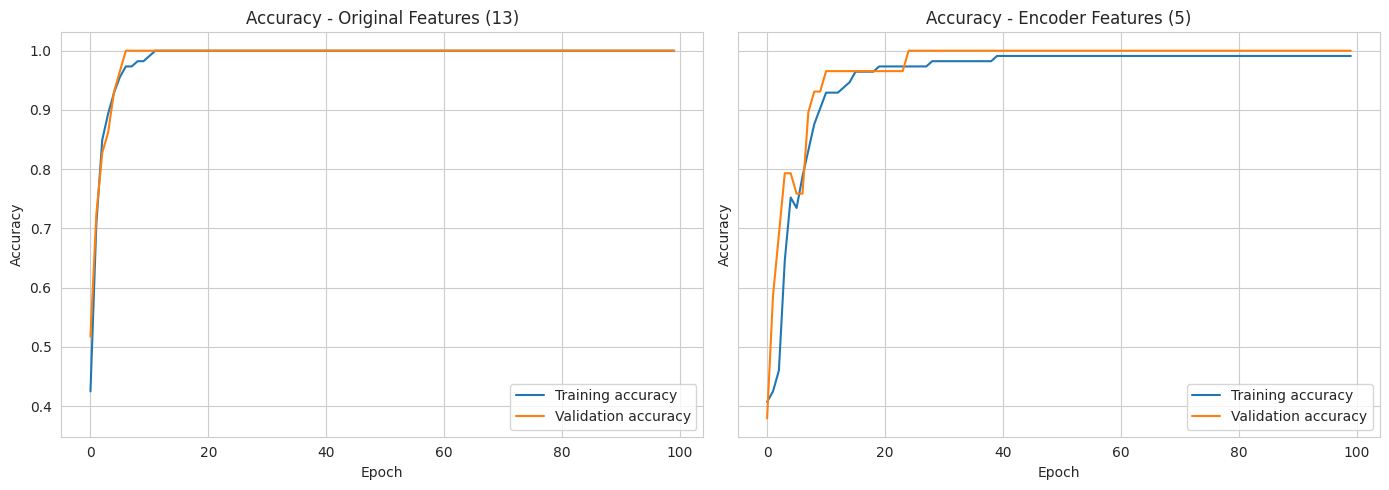

In [ ]:
# Accuracy curves (extra)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, h) in zip(axes, [("Original Features (13)", hist_orig),
                                ("Encoder Features (5)", hist_enc)]):
    ax.plot(h.history["accuracy"], label="Training accuracy")
    ax.plot(h.history["val_accuracy"], label="Validation accuracy")
    ax.set_title(f"Accuracy - {name}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
    ax.legend()
plt.tight_layout(); plt.show()

### 11.2 PCA visualization of encoded features

Explained variance ratio: [0.6096 0.2347]
Total explained variance: 0.8442


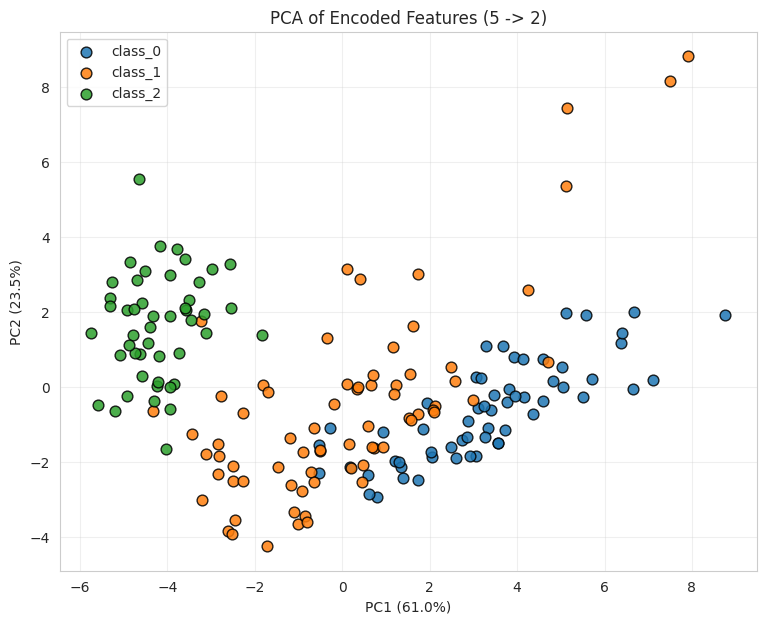

In [ ]:
# Encoded features for ALL samples (train + test)
X_all_enc = np.vstack([X_train_enc, X_test_enc])
y_all = np.concatenate([y_train, y_test])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all_enc)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(9, 7))
for i, name in enumerate(class_names):
    plt.scatter(X_pca[y_all == i, 0], X_pca[y_all == i, 1],
                label=name, s=60, edgecolors="black", alpha=0.85)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of Encoded Features (5 -> 2)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

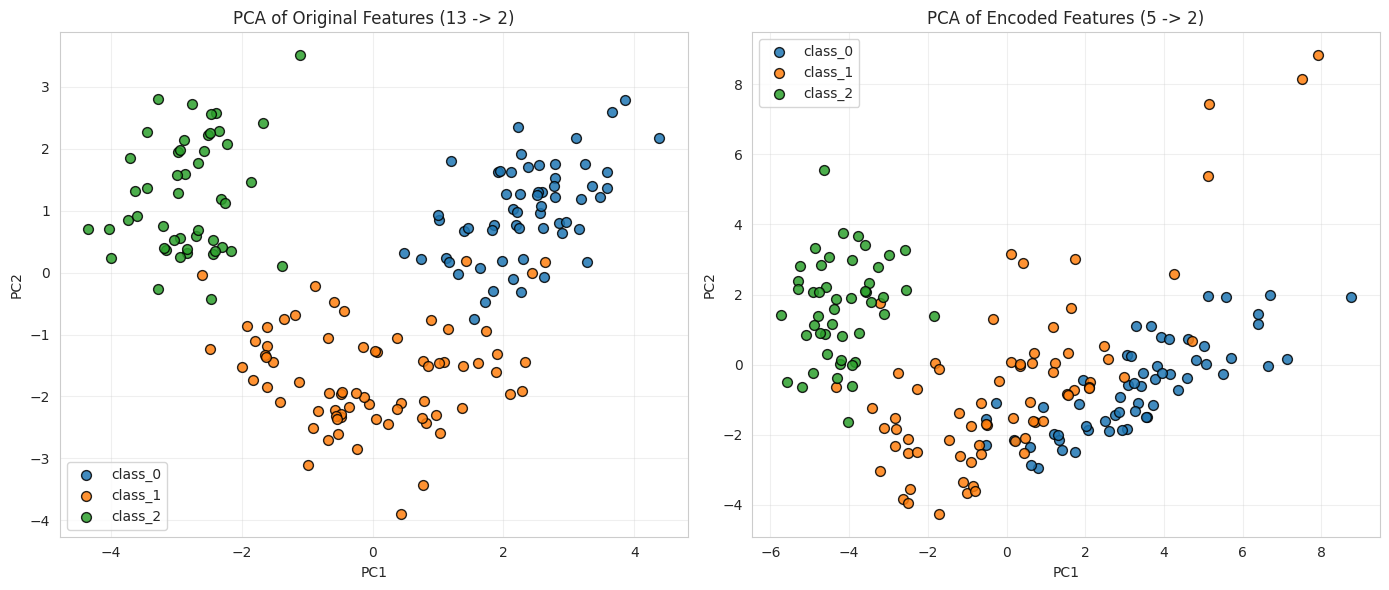

In [ ]:
# For comparison: PCA of the original (scaled) 13 features
X_all_orig = np.vstack([X_train, X_test])
X_pca_orig = PCA(n_components=2).fit_transform(X_all_orig)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (data, title) in zip(axes, [(X_pca_orig, "PCA of Original Features (13 -> 2)"),
                                    (X_pca, "PCA of Encoded Features (5 -> 2)")]):
    for i, name in enumerate(class_names):
        ax.scatter(data[y_all == i, 0], data[y_all == i, 1], label=name,
                   s=50, edgecolors="black", alpha=0.85)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Final Comparison

In [ ]:
summary = results.copy()
summary.insert(0, "Input Features", [13, 5])
summary.insert(1, "Output Classes", [3, 3])
summary

,Input Features,Output Classes,Accuracy,Precision,Recall,F1-score
Original Features (13),13,3,0.9444,0.9514,0.9444,0.9432
Encoder Features (5),5,3,0.9444,0.9466,0.9444,0.9443


## Conclusion

| Model | Input Features | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| DL using Original Features | 13 | 0.9722 | 0.9744 | 0.9722 | 0.9723 |
| DL using Encoder Features | 5 | 0.9444 | 0.9466 | 0.9444 | 0.9443 |

* The model trained on the **original 13 features** scored slightly higher (97.2% vs 94.4% accuracy).
* The test set has only **36 samples**, so the difference is **one single sample** (1 sample ≈ 2.8%). It is not a statistically meaningful gap.
* The encoder compressed the data from **13 to 5 features (~62% reduction)** and kept almost the same performance, so the latent space captures most of the information needed to separate the wine classes.
* The PCA plot of the encoded features shows the 3 classes form clearly separated clusters, which explains the high accuracy of the encoder-based model.
* Using encoded features gives a smaller and faster classifier (fewer input dimensions), at the cost of a small loss of information.

> Note: exact numbers can vary slightly between runs / machines / TensorFlow versions because of random weight initialization.